In [2]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = '/egr/research-slim/luozishe/IEDClassification/SpikeNet2'
PATIENTS = ['20551', '20556', '20558', '20559']

d = pd.read_csv(f'{ROOT}/hf_spikenet/lut_all.csv', sep=';')
d['patient'] = d['eeg_file'].str.split('_Run').str[0]
d['run']     = d['eeg_file'].str.split('_Run').str[1].astype(int)
d['t']       = d['event_file'].str.rsplit('_', n=1).str[1].astype(int) / 200   # clip center (s)
d['ied']     = d['fraction_of_yes'] >= 0.5
d = d[d['patient'].isin(PATIENTS)].reset_index(drop=True)

d.groupby('patient').agg(clips=('ied', 'size'), IEDs=('ied', 'sum'), runs=('run', 'nunique'))

,clips,IEDs,runs
patient,,,
20551,372,62,3
20556,156,26,3
20558,228,38,4
20559,192,32,2


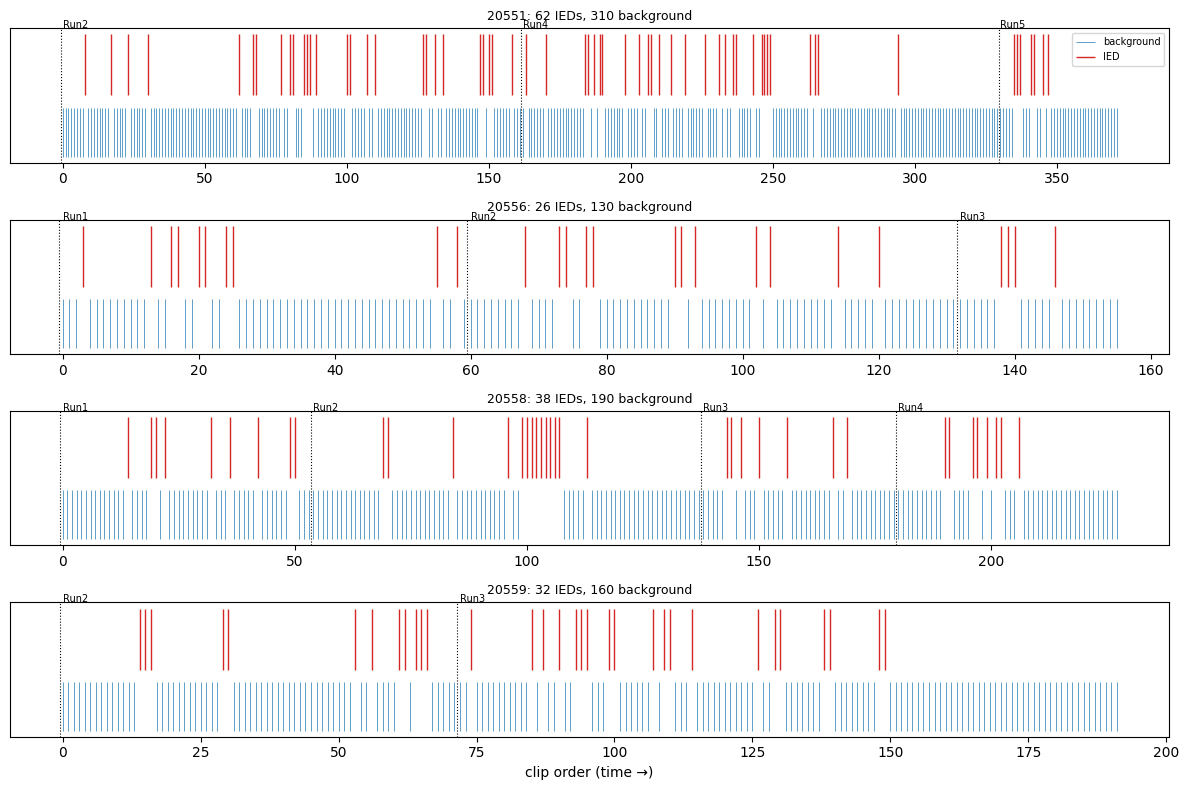

In [3]:
d = d.sort_values(['patient', 'run', 't']).reset_index(drop=True)
d['pos'] = d.groupby('patient').cumcount()            # clip order within each patient (runs back to back)

fig, axes = plt.subplots(len(PATIENTS), 1, figsize=(12, 2 * len(PATIENTS)))
for ax, pid in zip(axes, PATIENTS):
    g = d[d['patient'] == pid]
    ax.vlines(g.loc[~g['ied'], 'pos'], 0, 0.4, color='tab:blue', lw=0.5, label='background')
    ax.vlines(g.loc[g['ied'], 'pos'], 0.5, 1, color='tab:red', lw=1, label='IED')
    for r, gr in g.groupby('run'):                       # run boundaries
        ax.axvline(gr['pos'].min() - 0.5, c='k', ls=':', lw=0.8)
        ax.text(gr['pos'].min(), 1.05, f'Run{r}', fontsize=7)
    ax.set_yticks([]); ax.set_title(f'{pid}: {g["ied"].sum()} IEDs, {(~g["ied"]).sum()} background', fontsize=9)
axes[0].legend(loc='upper right', fontsize=7); axes[-1].set_xlabel('clip order (time →)')
plt.tight_layout(); plt.show()

20551: 62 IEDs → train 37, val 13, test 12 | cuts at clip 206.5, 248.5
20556: 26 IEDs → train 16, val 5, test 5 | cuts at clip 90.5, 117.0
20558: 38 IEDs → train 23, val 7, test 8 | cuts at clip 128.0, 179.5
20559: 32 IEDs → train 19, val 7, test 6 | cuts at clip 97.0, 127.5


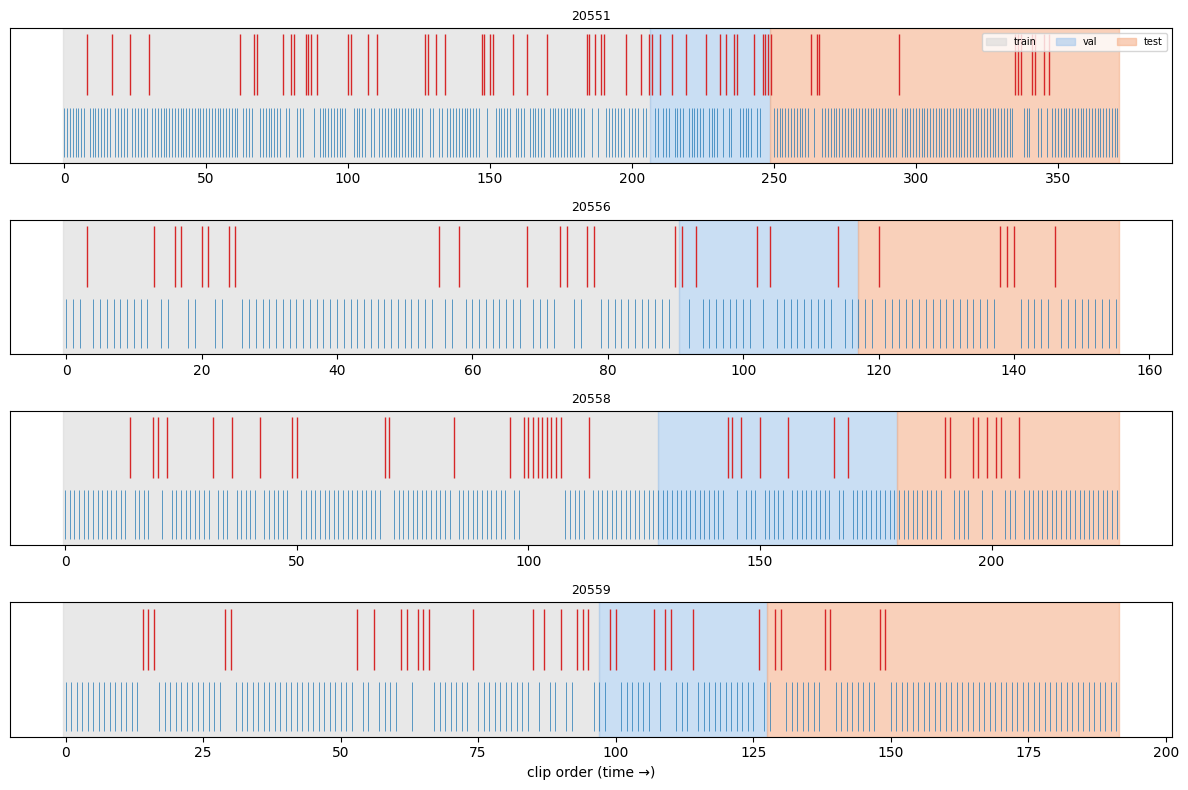

In [4]:
cuts = {}
for pid in PATIENTS:
    g = d[d['patient'] == pid]
    ied_pos = g.loc[g['ied'], 'pos'].values                    # positions of the IEDs, in time order
    n = len(ied_pos)
    i1, i2 = int(round(0.6 * n)), int(round(0.8 * n))          # first val IED, first test IED
    c1 = (ied_pos[i1 - 1] + ied_pos[i1]) / 2                   # cut halfway between neighbouring IEDs
    c2 = (ied_pos[i2 - 1] + ied_pos[i2]) / 2
    cuts[pid] = (c1, c2)
    print(f'{pid}: {n} IEDs → train {i1}, val {i2 - i1}, test {n - i2} | cuts at clip {c1:.1f}, {c2:.1f}')

fig, axes = plt.subplots(len(PATIENTS), 1, figsize=(12, 2 * len(PATIENTS)))
for ax, pid in zip(axes, PATIENTS):
    g = d[d['patient'] == pid]; c1, c2 = cuts[pid]; end = g['pos'].max() + 0.5
    for x0, x1, col, lab in [(-0.5, c1, '#d9d9d9', 'train'), (c1, c2, '#a6c8ec', 'val'), (c2, end, '#f5b28c', 'test')]:
        ax.axvspan(x0, x1, color=col, alpha=0.6, label=lab)
    ax.vlines(g.loc[g['ied'], 'pos'], 0.5, 1, color='tab:red', lw=1)
    ax.vlines(g.loc[~g['ied'], 'pos'], 0, 0.4, color='tab:blue', lw=0.5)
    ax.set_yticks([]); ax.set_title(pid, fontsize=9)
axes[0].legend(loc='upper right', fontsize=7, ncol=3); axes[-1].set_xlabel('clip order (time →)')
plt.tight_layout(); plt.show()

In [5]:
GAP = 30                                                  # seconds
OUT = f'{ROOT}/hf_spikenet/PerPatient'; os.makedirs(OUT, exist_ok=True)
cols = ['event_file', 'eeg_file', 'total_votes_received', 'fraction_of_yes', 'Mode']

parts = []
for pid in PATIENTS:
    g = d[d['patient'] == pid].copy(); c1, c2 = cuts[pid]
    g['Mode'] = np.select([g['pos'] < c1, g['pos'] < c2], ['Train', 'Val'], 'Test')

    # drop background clips within GAP s of an IED that belongs to a DIFFERENT split (same run)
    ied = g[g['ied']]
    near_other = np.zeros(len(g), bool)
    for i, (run, t, mode) in enumerate(zip(g['run'], g['t'], g['Mode'])):
        same_run = ied[ied['run'] == run]
        near_other[i] = ((np.abs(same_run['t'] - t) < GAP) & (same_run['Mode'] != mode)).any()
    dropped = (~g['ied'] & near_other).sum()
    g = g[g['ied'] | ~near_other]

    g[cols].to_csv(f'{OUT}/lut_{pid}.csv', sep=';', index=False)
    parts.append(g)
    print(f'{pid}: dropped {dropped} boundary background clips → saved lut_{pid}.csv')

S = pd.concat(parts)
summary = S.groupby(['patient', 'Mode'])['ied'].agg(clips='size', IEDs='sum').unstack('Mode')
summary = summary.reorder_levels([1, 0], axis=1)[['Train', 'Val', 'Test']]
summary

20551: dropped 27 boundary background clips → saved lut_20551.csv
20556: dropped 0 boundary background clips → saved lut_20556.csv
20558: dropped 0 boundary background clips → saved lut_20558.csv
20559: dropped 5 boundary background clips → saved lut_20559.csv


Mode    Train        Val       Test     
        clips IEDs clips IEDs clips IEDs
patient                                 
20551     202   37    28   13   115   12
20556      91   16    26    5    39    5
20558     128   23    52    7    48    8
20559      96   19    28    7    63    6

In [6]:
CLIPS = f'{ROOT}/hf_spikenet/Events'
rows = []
for pid in PATIENTS:
    f = pd.read_csv(f'{OUT}/lut_{pid}.csv', sep=';')
    f['run'] = f['eeg_file'].str.split('_Run').str[1].astype(int)
    f['t']   = f['event_file'].str.rsplit('_', n=1).str[1].astype(int) / 200
    f['ied'] = f['fraction_of_yes'] >= 0.5

    # 1. right patient, right columns, no duplicates
    assert (f['eeg_file'].str.startswith(pid)).all(), f'{pid}: foreign clips'
    assert list(f.columns[:5]) == cols and f['event_file'].is_unique

    # 2. every clip file exists on disk
    missing = [e for e in f['event_file'] if not os.path.exists(f'{CLIPS}/{e}.npy')]

    # 3. smallest time gap between a train clip and a test clip in the same run
    def min_gap(a, b):
        gaps = [np.abs(b.loc[b['run'] == r, 't'].values[:, None] - a.loc[a['run'] == r, 't'].values[None]).min()
                for r in set(a['run']) & set(b['run']) if (b['run'] == r).any() and (a['run'] == r).any()]
        return min(gaps) if gaps else np.inf
    tr, va, te = (f[f['Mode'] == m] for m in ['Train', 'Val', 'Test'])

    rows.append(dict(patient=pid, clips=len(f), missing=len(missing),
                     train_IED=int(tr['ied'].sum()), val_IED=int(va['ied'].sum()), test_IED=int(te['ied'].sum()),
                     gap_train_val_s=round(min_gap(tr, va), 1), gap_val_test_s=round(min_gap(va, te), 1),
                     gap_train_test_s=round(min_gap(tr, te), 1)))

check = pd.DataFrame(rows).set_index('patient'); check

,clips,missing,train_IED,val_IED,test_IED,gap_train_val_s,gap_val_test_s,gap_train_test_s
patient,,,,,,,,
20551,345,0,37,13,12,6.1,3.0,129.1
20556,156,0,16,5,5,16.5,36.0,308.1
20558,228,0,23,7,8,3.6,inf,inf
20559,187,0,19,7,6,27.3,22.8,234.6
